<span style="color: #E6E6E6;">
<span style="color: #E6E6E6; background-color: #00695C; padding:8px; display:block; border-left:4px solid #4682b4">

# Week 12: Positional encodings
The following is adapted from https://machinelearningmastery.com/a-gentle-introduction-to-positional-encoding-in-transformer-models-part-1/

In order to retain positional information about words in a sequence, we need a way of encoding it. The most obvious way would be a simple index indicating the order of the words (tokens), but this would have to be normalised to the range (0, 1) in order to work well for neural networks, and this becomes an issue for sequences of variable lengths. Instead, we create a vector for each word which encodes the positional information according to the following formulas: 

$$P(k, 2i) = sin(\frac{k}{n^{\frac{2i}{d}}})$$
$$P(k, 2i + 1) = cos(\frac{k}{n^{\frac{2i}{d}}})$$

- $k$ is the index of the token in question
- $d$ is the embedding dimension. Use a positive even integer so each sine column has a matching cosine column.
- $n$ is user defined, in the original paper they use $n=10,000$
- $i$ is used to create the sine then cosine pattern and runs over $0 \leq i < \frac{d}{2}$, so each value of $i$ fills two columns: column $2i$ (sine) and column $2i+1$ (cosine)
- $P(k,j)$ is the function that maps a position $k$ from the input sequence to the index $(k, j)$ in the positional matrix.

The formula ensures that at each index the position is represented using an alternating series of sine and cosine waves.

For training an NLP model using positional encodings, the positional encoding is simply added to the vector embeddings at each index, an efficient and elegant way of including the information!

</span>
</span>

<span style="color: #E6E6E6; background-color: #545454; padding:8px; display:block; border-left:4px solid #4682b4">

### Exercise 1: Understanding positional encodings

**1. Create the function `get_positional_encodings` which takes the sequence length, $d$ and $n$ as inputs and outputs a matrix which represents $P$**

*Use numpy!*

</span>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
 
def get_positional_encodings(seq_len, d, n=10000):
    if d <= 0 or d % 2 != 0:
        raise ValueError("d must be a positive even integer")
    P = np.zeros((seq_len, d))
    for k in range(seq_len):
        for i in range(d // 2):
            denominator = np.power(n, 2*i/d)
            P[k, 2*i] = np.sin(k/denominator)
            P[k, 2*i+1] = np.cos(k/denominator)
    return P
 
P = get_positional_encodings(seq_len=4, d=4, n=100)
print(P)

Matplotlib is building the font cache; this may take a moment.


[[ 0.          1.          0.          1.        ]
 [ 0.84147098  0.54030231  0.09983342  0.99500417]
 [ 0.90929743 -0.41614684  0.19866933  0.98006658]
 [ 0.14112001 -0.9899925   0.29552021  0.95533649]]


<span style="color: #E6E6E6; background-color: #545454; padding:8px; display:block; border-left:4px solid #4682b4">

**2. Now to understand what the encodings look like we will first plot the sinusoidals (columns of $P$) along with the points of each of the indices use the following function:**
- Try with sentences of different lengths

</span>

In [2]:
def plotSinusoid(y, plot_line=False, points_names=None, title=""):
    x = range(len(y))
    if plot_line:
        plt.plot(x, y,)
        if points_names is not None:
            for i, name in enumerate(points_names):
                plt.scatter(x[i], y[i], label=name)
    else:
        plt.scatter(x, y, marker="o")
    plt.title(title)

*We use a sequence length longer than the example sentence, just to make the plot look nicer*

In [3]:
example_sentence = "We walk when wearing what?"
P = get_positional_encodings(seq_len=len(example_sentence.split()) + 20, d=100, n=10_000)

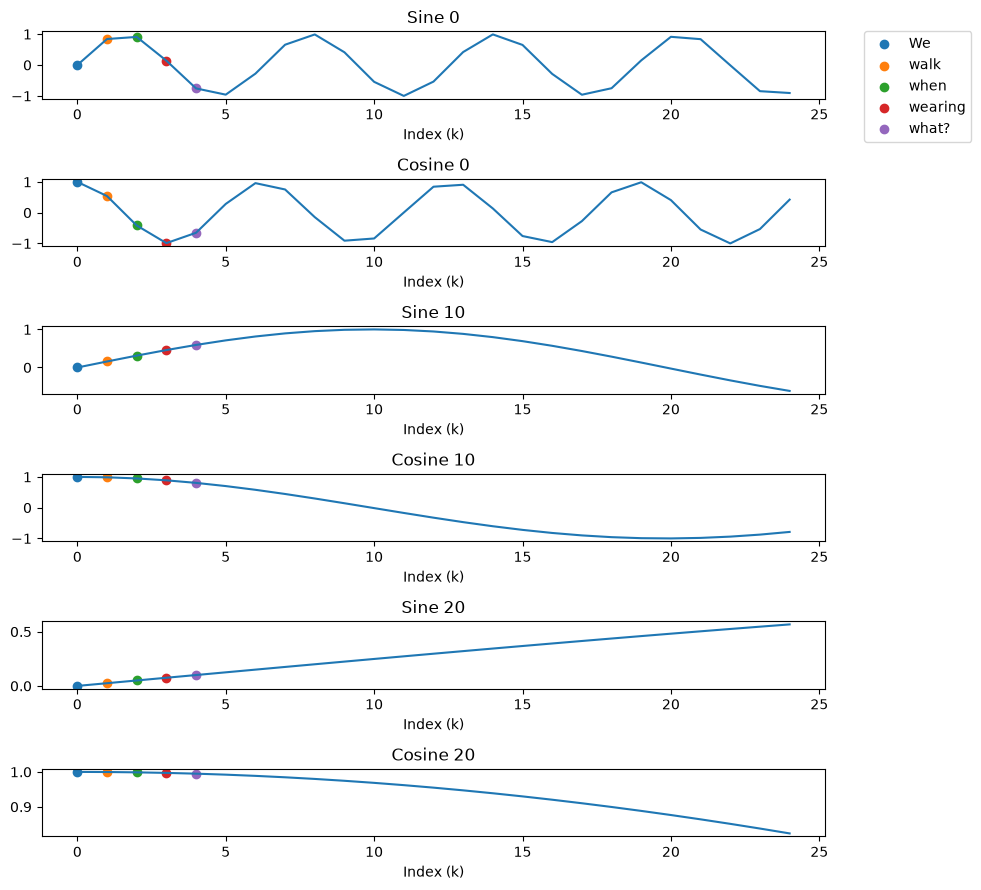

In [4]:
idxs = [0, 20, 40]
idxs.extend([el + 1 for el in  idxs])
idxs = sorted(idxs)
num_sinusoidals = len(idxs)
fig = plt.figure(figsize=(10, num_sinusoidals*1.5))    

for j, idx in enumerate(idxs):
    plt.subplot(num_sinusoidals, 1, j + 1)
    plotSinusoid(P[:, idx], plot_line=True, points_names=example_sentence.split())
    plt.title(f"{'Sine' if idx % 2 == 0 else 'Cosine'} {idx // 2}")
    plt.xlabel("Index (k)")
    if j == 0:
        plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
        
        
plt.tight_layout()
plt.show()

Now we will look at the actual positional encodings of each $k$:

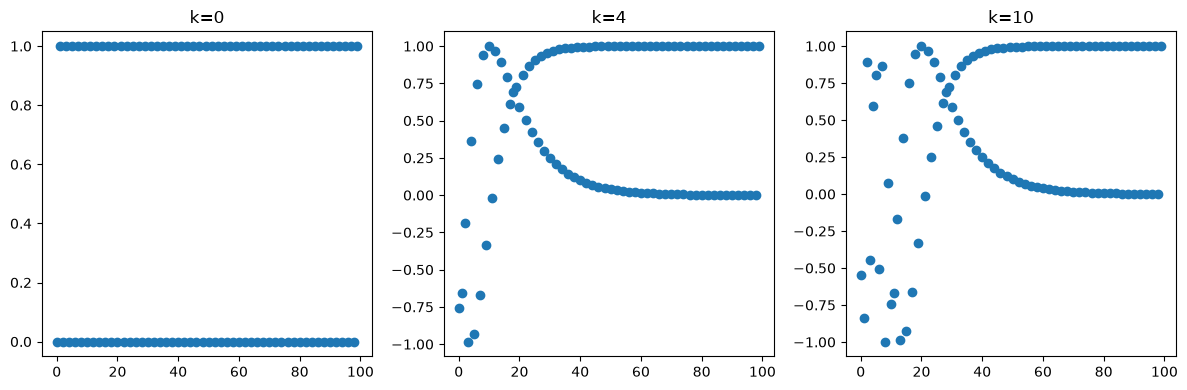

In [5]:
ks = [0, 4, 10, ]

fig = plt.figure(figsize=(len(ks)*4, 4))    
# Plot sine
for j, k in enumerate(ks):
    plt.subplot(1, len(ks), j + 1)
    plotSinusoid(P[k], title=f"k={k}")

plt.tight_layout()
plt.show()


And now let's inspect the entire matrix as a heatmap

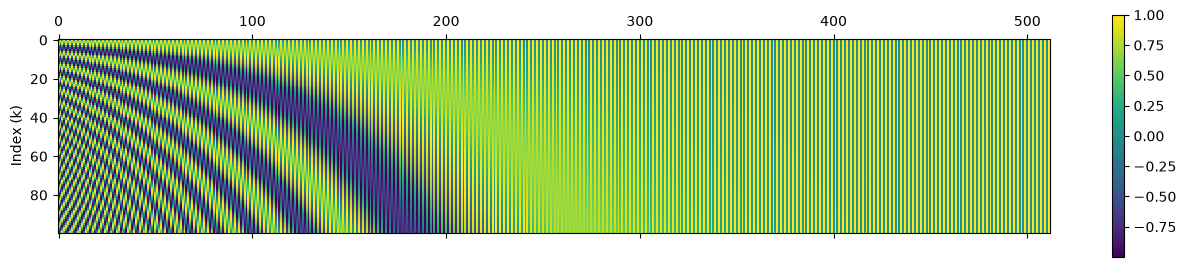

In [6]:
P = get_positional_encodings(seq_len=100, d=512, n=10000)
cax = plt.matshow(P)
plt.gcf().colorbar(cax)
plt.ylabel("Index (k)")
plt.show()

<span style="color: #E6E6E6; background-color: #545454; padding:8px; display:block; border-left:4px solid #4682b4">

### Exercise 2: Applying positional encodings to attention heads

In this exercise we will apply the positional encodings in the attention heads seen in week 11. We will also apply masked attention in order to illustrate how these two things make up a transformer. We will NOT be training our own transformer as this is an extremely time-consuming process if we want anything resembling decent results, both in pre-processing the text and in computation.

Positional encodings are applied to the word vectors BEFORE running attention and is done by simply adding the positional encoding vector to the word embeddings.

</span>

In [7]:
import torch
import torch.nn
import torch.nn.functional as F

<span style="color: #E6E6E6; background-color: #545454; padding:8px; display:block; border-left:4px solid #4682b4">

**1. Re-write the `get_positional_encodings` so it uses pytorch instead of numpy in the function `get_positional_encodings_torch`**

*Nothing much should change. One pitfall: `torch.pow` needs a tensor as one of its inputs, so `torch.pow(n, 2*i/d)` fails if `i` is a plain Python int. Loop over `torch.arange(...)` instead of `range(...)`, or write `n ** (2*i/d)`.*

</span>

In [8]:
def get_positional_encodings_torch(seq_len, d, n=10000):
    if d <= 0 or d % 2 != 0:
        raise ValueError("d must be a positive even integer")
    P = torch.zeros((seq_len, d))
    for k in range(seq_len):
        for i in torch.arange(d // 2):
            denominator = torch.pow(n, 2*i/d)
            P[k, 2*i] = torch.sin(k/denominator)
            P[k, 2*i+1] = torch.cos(k/denominator)
    return P

<span style="color: #E6E6E6; background-color: #545454; padding:8px; display:block; border-left:4px solid #4682b4">

**2. Run the following cell to build a vocabulary from the example sentences using the Week 11 helper.**

</span>

In [9]:
def build_vocabulary(sentences, oov_token='OOV'):

    # Make a set to represent our vocabulary
    # A set is like a dict with keys, but no values
    # Really more like a list that cannot have duplicates
    vocab = set()

    # Iterate through sentences, lowercase and split the sentences to obtain lists of words used, add these to vocab
    for sentence in sentences:
        words = sentence.lower().split()
        vocab.update(words)

    # Add the only special token we use: OOV (out of vocabulary)
    vocab.update([oov_token])

    # Sort vocab, just to make it nicer to look around in
    vocab = sorted(vocab)

    # Create the dictionaries word_to_index (word -> index) and index_to_word (index -> word)
    word_to_index = {word: idx for idx, word in enumerate(vocab)}
    index_to_word = {idx: word for word, idx in word_to_index.items()}

    # Define function for getting token indices from a list of tokens, should return the index of OOV if a word is not in vocab
    def tokens_to_indices(tokens):
        return [word_to_index[word] if word in word_to_index else word_to_index[oov_token] for word in tokens]

    return tokens_to_indices, word_to_index, index_to_word, vocab

# Build a small vocabulary from everyday sentences.
sentences = [
    "The train leaves the station at noon",
    "We cycle to campus when the weather is dry",
    "The library opens early on Monday",
    "A student reads a book on the bus",
    "We walk to the park after lunch",
    "The last bus stops near the library",
]

# Create vocab based on sentences:
tokens_to_indices, word_to_index, index_to_word, vocab = build_vocabulary(sentences=sentences)


<span style="color: #E6E6E6; background-color: #545454; padding:8px; display:block; border-left:4px solid #4682b4">

**3. Make a new attribute in the `AttentionModule` holding the matrix returned by `get_positional_encodings_torch`, and add it to the word embeddings before running attention:**

- The matrix needs one row per *position* in the sentence (not one per word in the vocabulary), so it is created with `max_seq_len` rows
- $\star$ (Optional exercise) A sentence longer than `max_seq_len` will crash the module. Implement a solution which ensures the matrix is always large enough for a sentence of any length.

</span>

In [10]:
class AttentionModule:
    def __init__(self, word_dim, Q_dim, K_dim, V_dim, max_seq_len=100):
        # Create dummy embedding layer for word embeddings:
        # A torch embedding layer is just like a linear layer that only takes tensors of integers (technically torch.long values)
        self.word_embeddings = torch.nn.Embedding(len(vocab), word_dim)

        # Positional encodings: one row per position in the sentence (up to max_seq_len), one column per embedding dimension
        self.word_dim = word_dim
        self.positional_encoding_matrix = get_positional_encodings_torch(seq_len=max_seq_len, d=word_dim)

        # Define weight matrices for Queries, Keys and Values
        # Unlike the word embeddings, these need to work on torch tensors, so they are just linear layers, despite being used much like embeddings
        self.query_embeddings = torch.nn.Linear(word_dim, Q_dim)
        self.key_embeddings = torch.nn.Linear(word_dim, K_dim)
        self.value_embeddings = torch.nn.Linear(word_dim, V_dim)

        # Keep track of K_dim for scaling factors, otherwise handled by number of heads in multihead attention
        self.K_dim = K_dim

    def attention_from_tokens(self, token_indices, mask=False):
        # Transform to tensor to allow or use in word_embeddings:
        token_indices_tensor = torch.tensor(token_indices)
        embeddings = self.word_embeddings(token_indices_tensor)
        seq_len = embeddings.shape[0]

        # (Optional exercise) If the sentence is longer than the matrix, make a new, bigger matrix
        if seq_len > self.positional_encoding_matrix.shape[0]:
            self.positional_encoding_matrix = get_positional_encodings_torch(seq_len=seq_len, d=self.word_dim)

        # Add the positional encodings to the word embeddings (only the first seq_len rows are needed)
        embeddings = embeddings + self.positional_encoding_matrix[:seq_len]

        queries = self.query_embeddings(embeddings)
        keys = self.key_embeddings(embeddings)
        values = self.value_embeddings(embeddings)

        # Attention scores (before softmax)
        scores = (queries @ keys.T) / self.K_dim ** 0.5

        # Mask out future words: entry (q, k) with k > q means word q attending to a word that comes after it
        # These are set to -inf BEFORE the softmax, so the softmax gives them a weight of exactly 0 and each row still sums to 1
        if mask:
            future_words = torch.triu(torch.ones(seq_len, seq_len), diagonal=1).bool()  # True above the diagonal
            scores = scores.masked_fill(future_words, float('-inf'))

        # Softmax over the last dimension (the keys), so each row sums to 1
        attention = F.softmax(scores, dim=-1)

        representations = attention @ values

        return attention, representations


In [11]:
def visualize_attention(attention_map, sentence_1: list[str], sentence_2: list[str], head: int = None):
    """
    Visualize the attention map between two sentences.

    Parameters:
        attention_map (numpy.ndarray): 2D array with attention weights. Shape: (len(sentence_1), len(sentence_2))
            (or 3D with shape (num_heads, len(sentence_1), len(sentence_2)) if head is given)
        sentence_1 (list of str): The first sentence, tokenized into words.
        sentence_2 (list of str): The second sentence, tokenized into words.
        head (int, optional): Which attention head to plot, for multi-head attention.
    """

    if head is not None:
        attention_map = attention_map[head]

    # Ensure the attention map dimensions match the sentences
    assert attention_map.shape == (len(sentence_1), len(sentence_2)), (
        "Attention map shape must match sentence lengths"
    )

    # Width follows sentence 2 (x-axis), height follows sentence 1 (y-axis)
    fig, ax = plt.subplots(figsize=(max(4, len(sentence_2)), max(4, len(sentence_1))))
    cax = ax.matshow(attention_map, cmap='viridis', aspect='auto')

    # Add color bar
    plt.colorbar(cax, ax=ax, orientation='vertical')

    # Set up ticks and labels
    ax.set_xticks(np.arange(len(sentence_2)))
    ax.set_yticks(np.arange(len(sentence_1)))
    ax.set_xticklabels(sentence_2, rotation=90, fontsize=10)
    ax.set_yticklabels(sentence_1, fontsize=10)

    # Add labels for clarity
    ax.set_xlabel('Words in Sentence 2', fontsize=12)
    ax.set_ylabel('Words in Sentence 1', fontsize=12)
    plt.title('Attention Map', fontsize=14)

    if head is not None:
        plt.title(f'Attention Map for head {head}', fontsize=14)

    plt.tight_layout()
    plt.show()

In [12]:
# Create a new sentence by randomly sampling from vocab...
# (seeded, so everyone gets the same sentence - feel free to change the seed)
np.random.seed(42)
new_sentence = " ".join(np.random.choice(vocab, 5))
# Add extra word just to showcase OOV tokens also being used
new_sentence += " factorio"
print("Random sentence is", new_sentence)

# Get tokens from the new sentence:
tokens = new_sentence.lower().split()
print("Tokens are", tokens)
token_indices = tokens_to_indices(tokens)


Random sentence is campus opens walk lunch is factorio
Tokens are ['campus', 'opens', 'walk', 'lunch', 'is', 'factorio']


campus opens walk lunch is factorio
Attention dimensionality is: torch.Size([6, 6])
After context layer (dotting with values, dimension is): torch.Size([6, 50])


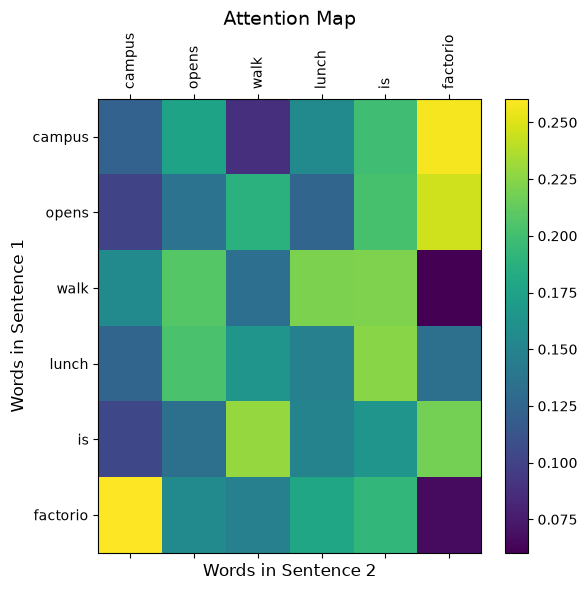

In [13]:
# Define dimensions of word embeddings, as well as Q, K and V matrices
word_dim = 50
Q_dim = 50
K_dim = 50
V_dim = 50

# Instantiate AttentionModule
attention_model = AttentionModule(word_dim, Q_dim, K_dim, V_dim)

# Print sentence we are getting attention for
print(new_sentence)

# Calculate the attention and context layer values
attention, representations = attention_model.attention_from_tokens(token_indices)

# Print and visualize
print("Attention dimensionality is:", attention.shape)
print("After context layer (dotting with values, dimension is):", representations.shape)

visualize_attention(attention.detach().numpy(), new_sentence.split(), new_sentence.split())

<span style="color: #E6E6E6; background-color: #545454; padding:8px; display:block; border-left:4px solid #4682b4">

**4. Now apply masked attention to the module using a boolean value in the method `attention_from_tokens` that allows you to toggle it on and off. This is done in order to avoid leakage from future words when training a model to predict the next word (like most generative chatbots do)**

*On the above attention map, think about what part of it has to be masked out. The masking has to happen on the attention scores **before** the softmax, so that each row of the attention map still sums to 1. Which value can you give a score so that the softmax turns it into exactly 0?*

</span>

Attention dimensionality is: torch.Size([6, 6])
After context layer (dotting with values, dimension is): torch.Size([6, 50])
Rows of the attention map sum to: [1. 1. 1. 1. 1. 1.]


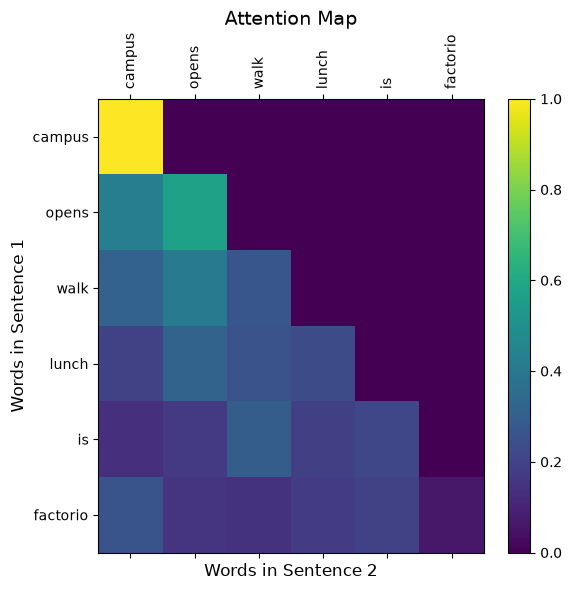

In [14]:
attention, representations = attention_model.attention_from_tokens(token_indices, mask=True)

# Print and visualize
print("Attention dimensionality is:", attention.shape)
print("After context layer (dotting with values, dimension is):", representations.shape)
# Sanity check: every row of the attention map should still sum to 1
print("Rows of the attention map sum to:", attention.sum(dim=-1).detach().numpy().round(3))

visualize_attention(attention.detach().numpy(), new_sentence.split(), new_sentence.split())


<span style="color: #E6E6E6; background-color: #545454; padding:8px; display:block; border-left:4px solid #4682b4">

**$\star \star \star$ 5. Apply masking and positional encodings to the `MultiHeadAttentionModule` from week 11**

Copy `MultiHeadAttentionModule` from the week 11 notebook into the cell below. It inherits from `AttentionModule`, so it now gets this week's `__init__` (including the positional encoding matrix), and you only need to change `attention_from_tokens`. Note that the scores now hold one attention map per head, with shape `(num_heads, seq_len, seq_len)`.

</span>

In [15]:
# Inherits from this week's AttentionModule, so __init__ already creates the positional encoding matrix
class MultiHeadAttentionModule(AttentionModule):
    def __init__(self, word_dim, Q_dim, K_dim, V_dim, num_heads=1):
        super().__init__(word_dim, Q_dim, K_dim, V_dim)

        # Difference from Attention Module, actually has a number of heads
        self.num_heads = num_heads

        # This time, we make the query, key and value layers num_heads times bigger (replacing the single-head ones from super().__init__)
        # Technically we should have a [num_heads, word_dim, Q_dim] dimensional weight tensor, but torch's linear layers only use 2-dimensional weight matrices...
        # ... so we just increase the number of Q_dims and then we can reshape afterwards
        self.query_embeddings = torch.nn.Linear(word_dim, Q_dim * num_heads)
        self.key_embeddings = torch.nn.Linear(word_dim, K_dim * num_heads)
        self.value_embeddings = torch.nn.Linear(word_dim, V_dim * num_heads)

        # This time, we actually need all of our Q, K and V dims for reshaping purposes...
        self.Q_dim = Q_dim
        self.K_dim = K_dim
        self.V_dim = V_dim

        # Final linear layer to combine the results of all heads into one...
        self.linear_layer = torch.nn.Linear(in_features=V_dim * num_heads, out_features=V_dim)

    def attention_from_tokens(self, token_indices, mask=False):
        # Transform to tensor, so it can be used in word_embeddings:
        token_indices_tensor = torch.tensor(token_indices)
        embeddings = self.word_embeddings(token_indices_tensor)
        sentence_length = len(token_indices)

        # NEW: (Optional exercise) If the sentence is longer than the matrix, make a new, bigger matrix
        if sentence_length > self.positional_encoding_matrix.shape[0]:
            self.positional_encoding_matrix = get_positional_encodings_torch(seq_len=sentence_length, d=self.word_dim)

        # NEW: Add the positional encodings to the word embeddings, exactly as in the single-head module
        embeddings = embeddings + self.positional_encoding_matrix[:sentence_length]

        # Multi-head queries, keys and values, each of shape (num_heads, sentence_length, Q/K/V_dim)
        queries = self.query_embeddings(embeddings).view(sentence_length, self.num_heads, self.Q_dim).permute(1, 0, 2)
        keys = self.key_embeddings(embeddings).view(sentence_length, self.num_heads, self.K_dim).permute(1, 0, 2)
        values = self.value_embeddings(embeddings).view(sentence_length, self.num_heads, self.V_dim).permute(1, 0, 2)

        # Attention scores (before softmax), shape (num_heads, sentence_length, sentence_length)
        scores = torch.einsum('hqd,hkd->hqk', queries, keys) / self.K_dim ** 0.5

        # NEW: Mask out future words BEFORE the softmax
        # The mask has shape (sentence_length, sentence_length) and is broadcast over the heads, so every head gets the same mask
        if mask:
            future_words = torch.triu(torch.ones(sentence_length, sentence_length), diagonal=1).bool()
            scores = scores.masked_fill(future_words, float('-inf'))

        # Softmax over the last dimension (the keys), so each row of each head sums to 1
        heads_attention = F.softmax(scores, dim=-1)  # (num_heads, sentence_length, sentence_length)
        heads_representations = heads_attention @ values  # (num_heads, sentence_length, V_dim)

        # Combine the heads: (words, heads, V_dim) -> (words, heads * V_dim), then pass through the final linear layer
        heads_representations = heads_representations.permute(1, 0, 2).contiguous().view(sentence_length, self.num_heads * self.V_dim)
        final_representations = self.linear_layer(heads_representations)

        return heads_attention, final_representations


Attention dimensionality is: torch.Size([2, 6, 6])
Final representations dimensionality is: torch.Size([6, 50])
Rows of the attention maps sum to: [[1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1.]]


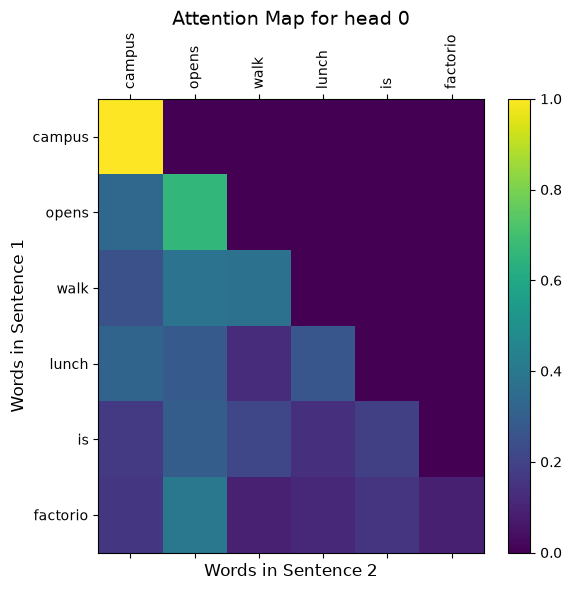

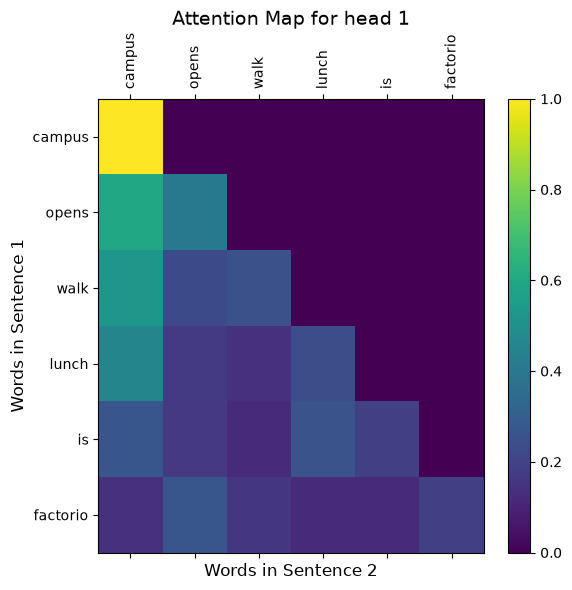

In [16]:
# Instantiate MultiHeadAttentionModule with a few heads
num_heads = 2
multi_head_model = MultiHeadAttentionModule(word_dim, Q_dim, K_dim, V_dim, num_heads=num_heads)

heads_attention, final_representations = multi_head_model.attention_from_tokens(token_indices, mask=True)

print("Attention dimensionality is:", heads_attention.shape)
print("Final representations dimensionality is:", final_representations.shape)
# Sanity check: every row of every head's attention map should still sum to 1
print("Rows of the attention maps sum to:", heads_attention.sum(dim=-1).detach().numpy().round(3))

for head in range(num_heads):
    visualize_attention(heads_attention.detach().numpy(), new_sentence.split(), new_sentence.split(), head=head)
